## Experiment 1: Free-Space Path Loss and Received Power

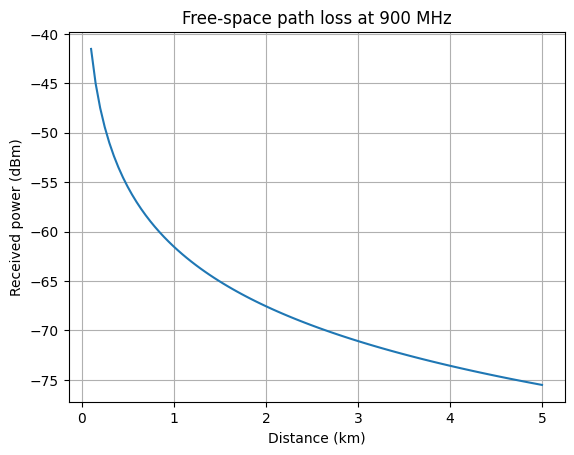

Received power at 0.1 km : -41.52 dBm
Received power at 5 km   : -75.5 dBm


In [1]:
import numpy as np
import matplotlib.pyplot as plt

d = np.linspace(0.1, 5, 100)              
f = 900                                   
fspl = 20*np.log10(d) + 20*np.log10(f) + 32.44   
pr = 30 - fspl                            

plt.plot(d, pr)
plt.xlabel("Distance (km)"); plt.ylabel("Received power (dBm)")
plt.title("Free-space path loss at 900 MHz"); plt.grid(True); plt.show()
print("Received power at 0.1 km :", round(pr[0], 2), "dBm")
print("Received power at 5 km   :", round(pr[-1], 2), "dBm")


## Experiment 2: Frequency (Co-channel) Reuse: Cluster Size, Capacity and S/I

N    Q    ch/cell  S/I(dB)
3     3.00   112.0   11.30
4     3.46    84.0   13.80
7     4.58    48.0   18.66
9     5.20    37.3   20.85
12    6.00    28.0   23.34


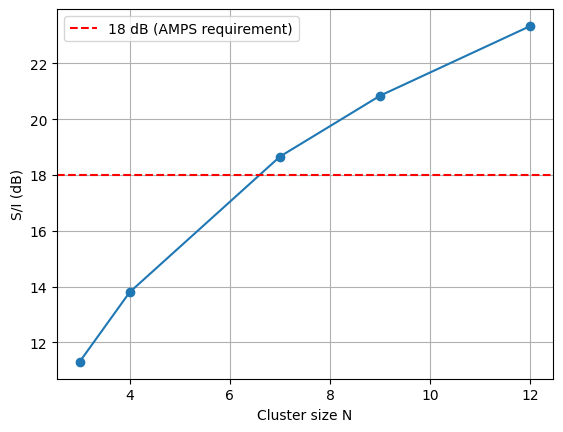

In [2]:
import numpy as np
import matplotlib.pyplot as plt

N = np.array([3, 4, 7, 9, 12])
gamma, total = 4, 336
Q = np.sqrt(3 * N)                        
ch = total / N                            
si_db = 10 * np.log10(Q**gamma / 6)       

print("N    Q    ch/cell  S/I(dB)")
for n, q, c, s in zip(N, Q, ch, si_db):
    print(f"{n:<4d} {q:5.2f} {c:7.1f} {s:7.2f}")

plt.plot(N, si_db, "o-")

plt.axhline(18, linestyle="--", color="r", label="18 dB (AMPS requirement)")
plt.xlabel("Cluster size N"); plt.ylabel("S/I (dB)")
plt.legend(); plt.grid(True); plt.show()


## Experiment 3: Call Blocking Probability using the Erlang B Formula

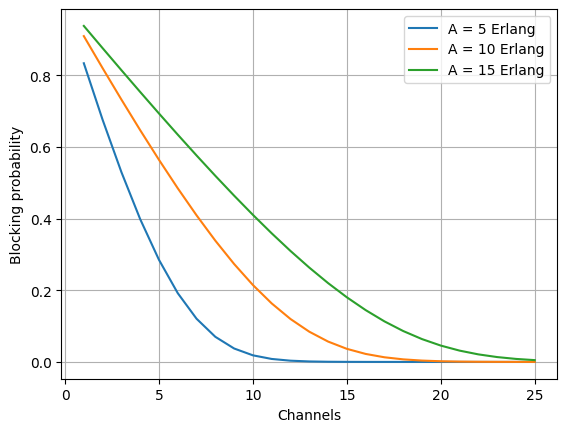

Blocking for A=10, C=15: 0.0365


In [3]:
import matplotlib.pyplot as plt

def erlang_b(A, C):                       
    B = 1.0
    for k in range(1, C + 1):
        B = A * B / (k + A * B)
    return B

channels = range(1, 26)
for A in (5, 10, 15):
    plt.plot(channels, [erlang_b(A, c) for c in channels], label=f"A = {A} Erlang")
plt.xlabel("Channels"); plt.ylabel("Blocking probability")
plt.legend(); plt.grid(True); plt.show()
print("Blocking for A=10, C=15:", round(erlang_b(10, 15), 4))


## Experiment 4: Handoff Simulation with Hysteresis

Handoff BS1 -> BS2 at 590 m


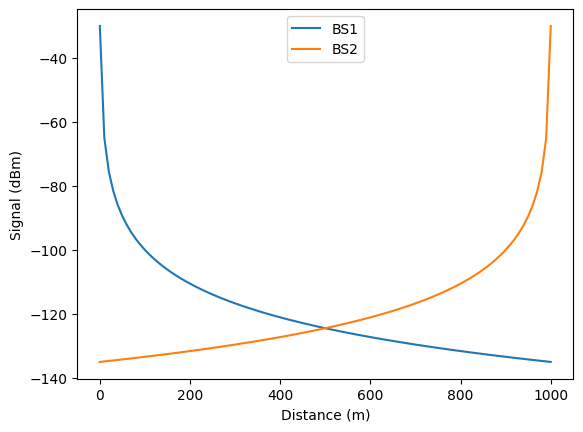

In [4]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(0, 1001, 10)                
p1 = -30 - 35*np.log10(np.maximum(x, 1))          
p2 = -30 - 35*np.log10(np.maximum(1000 - x, 1))   
H, serving = 5, 1                         

for i in range(len(x)):
    if serving == 1 and p2[i] > p1[i] + H:
        serving = 2
        print(f"Handoff BS1 -> BS2 at {x[i]} m")
        break

plt.plot(x, p1, label="BS1"); plt.plot(x, p2, label="BS2")
plt.xlabel("Distance (m)"); plt.ylabel("Signal (dBm)"); plt.legend(); plt.show()


## Experiment 5: Code Division Multiple Access (CDMA): Spreading and Despreading

In [5]:
import numpy as np

code1 = np.array([1, -1, 1, -1])   
code2 = np.array([1, 1, -1, -1])   
bit1 = 1                           
bit2 = -1                          

tx = bit1 * code1 + bit2 * code2 
print("Sent signal      :", tx)
print("User 1 recovered :", np.sign(tx @ code1 / 4))
print("User 2 recovered :", np.sign(tx @ code2 / 4))


Sent signal      : [ 0 -2  2  0]
User 1 recovered : 1.0
User 2 recovered : -1.0


## Experiment 6: Effect of OFDMA Downlink Scheduler on User Throughput and Fairness

In [6]:
import numpy as np
np.random.seed(1)
N_UE, N_RB, N_TTI = 4, 10, 1000
base = np.array([10, 7, 4, 1.5])          

def jain(x):
    return x.sum()**2 / (len(x) * (x**2).sum())

def run(policy):
    total = np.zeros(N_UE)
    avg = np.ones(N_UE)                   
    for t in range(N_TTI):
        rate = base * np.random.exponential(1, N_UE)  
        got = np.zeros(N_UE)
        for rb in range(N_RB):
            if policy == "MaxCI":
                u = np.argmax(rate)
            elif policy == "RR":
                u = (rb + t) % N_UE
            else:                        
                u = np.argmax(rate / avg)
            got[u] += rate[u]
        avg = 0.99 * avg + 0.01 * got
        total += got
    return total / N_TTI

for p in ["MaxCI", "RR", "PF"]:
    x = run(p)
    print(f"{p:6} per-UE = {np.round(x, 1)} Total = {x.sum():.1f} Jain = {jain(x):.3f}")


MaxCI  per-UE = [75.1 40.7 13.7  1.1] Total = 130.6 Jain = 0.569
RR     per-UE = [25.2 16.9  9.8  3.7] Total = 55.6 Jain = 0.750
PF     per-UE = [53.1 36.7 20.3  7.6] Total = 117.7 Jain = 0.747
